# Time Series Forecasting — Kaggle Notebook

**Sections**
1. [Config — set all paths here](#1-config)
2. [Imports & Reproducibility](#2-imports--reproducibility)
3. [Data Loading](#3-data-loading)
4. [Exploratory Data Analysis](#4-exploratory-data-analysis)
5. [Baselines & Evaluation Metrics](#5-baselines--evaluation-metrics)
6. [Feature Engineering](#6-feature-engineering)
7. [PyTorch Dataset & DataLoader](#7-pytorch-dataset--dataloader)
8. [Model Definition](#8-model-definition)
9. [Training Loop](#9-training-loop)
10. [Validation Inference](#10-validation-inference)
11. [Save & Submit](#11-save--submit)

---
## 1. Config

**Only edit the below cell.** Everything else reads from these variables.

In [1]:
from pathlib import Path

# ── Kaggle input paths (update if your dataset names differ) ──────────────────
DATA_DIR     = Path("/kaggle/input/datasets/xitij27/dlam-bonus-project-dataset/data")
BASELINE_DIR = Path("/kaggle/input/datasets/xitij27/baseline-code/baseline")
OUTPUT_DIR   = Path("/kaggle/working")

# ── Derived file paths (do not edit) ─────────────────────────────────────────
TRAIN_PATH      = DATA_DIR / "train.csv"
VAL_INPUT_PATH  = DATA_DIR / "validation_input.csv"
VAL_INDEX_PATH  = DATA_DIR / "forecast_index_validation.csv"
METADATA_PATH   = DATA_DIR / "metadata.json"
CHECKPOINT_PATH = OUTPUT_DIR / "best_checkpoint.pt"
VAL_PREDS_PATH  = OUTPUT_DIR / "validation_predictions.csv"

# ── Model / training hyper-parameters ────────────────────────────────────────
SEED        = 42
LOOKBACK    = 168    # hours of history fed into the model (1 week)
HORIZON     = 24     # hours predicted per forward pass
BATCH_SIZE  = 256    # T4 has 16 GB VRAM — safe to go up to 256
N_EPOCHS    = 100
LR          = 1e-3
WEIGHT_DECAY = 1e-4
VAL_FRAC    = 0.1    # fraction of sliding-window samples held out for loss monitoring
EVAL_HORIZON = 336   # held-out rows per series for local metric estimation

# ── Feature engineering knobs ─────────────────────────────────────────────────
LAGS    = [1, 2, 3, 6, 12, 24, 48, 168]
WINDOWS = [6, 24, 168]

# ── Sanity-check paths ────────────────────────────────────────────────────────
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for p in [TRAIN_PATH, VAL_INPUT_PATH, VAL_INDEX_PATH, BASELINE_DIR / "baselines.py"]:
    print(f"{'OK' if p.exists() else 'MISSING':8s} {p}")

OK       /kaggle/input/datasets/xitij27/dlam-bonus-project-dataset/data/train.csv
OK       /kaggle/input/datasets/xitij27/dlam-bonus-project-dataset/data/validation_input.csv
OK       /kaggle/input/datasets/xitij27/dlam-bonus-project-dataset/data/forecast_index_validation.csv
OK       /kaggle/input/datasets/xitij27/baseline-code/baseline/baselines.py


---
## 2. Imports & Reproducibility

In [2]:
import sys
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Add baseline folder to path
if str(BASELINE_DIR) not in sys.path:
    sys.path.insert(0, str(BASELINE_DIR))
from baselines import make_all_baselines

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Python  {sys.version.split()[0]}")
print(f"pandas  {pd.__version__}")
print(f"numpy   {np.__version__}")
print(f"torch   {torch.__version__}")
print(f"Device  {DEVICE}")
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    print(f"GPU     {torch.cuda.get_device_name(0)}")

Python  3.12.12
pandas  2.3.3
numpy   2.0.2
torch   2.10.0+cu128
Device  cuda
GPU     Tesla T4


---
## 3. Data Loading

In [3]:
train_df     = pd.read_csv(TRAIN_PATH,     parse_dates=["timestamp"])
val_input_df = pd.read_csv(VAL_INPUT_PATH, parse_dates=["timestamp"])
val_index_df = pd.read_csv(VAL_INDEX_PATH, parse_dates=["timestamp"])

metadata = {}
if METADATA_PATH.exists():
    with open(METADATA_PATH) as f:
        metadata = json.load(f)

series_ids = sorted(train_df["series_id"].unique())

print(f"train_df      {train_df.shape}")
print(f"val_input_df  {val_input_df.shape}")
print(f"val_index_df  {val_index_df.shape}")
print(f"Series count  {len(series_ids)}")
print(f"\nval_input_df columns:\n  {val_input_df.columns.tolist()}")
train_df.head(3)

train_df      (414720, 25)
val_input_df  (32256, 24)
val_index_df  (32256, 2)
Series count  96

val_input_df columns:
  ['series_id', 'timestamp', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'trend', 'workload_intensity', 'demand_forecast', 'staffing_forecast', 'upstream_quality_forecast', 'promotion_intensity', 'shock_risk', 'maintenance_known', 'unit_reliability_forecast', 'queue_pressure_forecast', 'network_pressure_forecast', 'event_load_forecast', 'service_irregularity_risk_forecast', 'throughput_disruption_risk_forecast', 'nominal_capacity', 'zone_sin', 'zone_cos']


,series_id,timestamp,hour_sin,hour_cos,dow_sin,dow_cos,is_weekend,trend,workload_intensity,demand_forecast,...,unit_reliability_forecast,queue_pressure_forecast,network_pressure_forecast,event_load_forecast,service_irregularity_risk_forecast,throughput_disruption_risk_forecast,nominal_capacity,zone_sin,zone_cos,target
0,unit_000,2023-01-01 00:00:00,0.000000,1.000000,-0.781831,0.62349,1.0,-1.731704,0.001633,0.027929,...,1.000000,1.768614,0.818472,0.160134,0.00000,0.063503,82.690278,0.0,1.0,2.989556
1,unit_000,2023-01-01 01:00:00,0.258819,0.965926,-0.781831,0.62349,1.0,-1.731010,0.004694,0.000000,...,0.887202,1.806212,1.816860,0.004240,0.08081,0.000000,82.690278,0.0,1.0,3.199527
2,unit_000,2023-01-01 02:00:00,0.500000,0.866025,-0.781831,0.62349,1.0,-1.730316,0.012069,0.110750,...,0.986113,NaN,2.596726,0.208973,0.00000,0.009573,82.690278,0.0,1.0,3.425670


---
## 4. Exploratory Data Analysis

In [4]:
# ── Per-series summary ────────────────────────────────────────────────────────
summary = (
    train_df.groupby("series_id")["target"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(3)
)
print(summary.describe().round(2))
summary.head()

        count   mean    std    min    max
count    96.0  96.00  96.00  96.00  96.00
mean   4320.0   9.91   5.24   0.60  37.03
std       0.0   1.66   0.75   0.27   6.00
min    4320.0   6.45   3.80   0.16  25.92
25%    4320.0   8.54   4.57   0.41  32.48
50%    4320.0  10.06   5.34   0.53  37.10
75%    4320.0  10.90   5.72   0.74  40.89
max    4320.0  14.38   7.12   1.61  53.00


,count,mean,std,min,max
series_id,,,,,
unit_000,4320,9.142,5.083,0.440,32.788
unit_001,4320,10.932,5.720,0.909,38.545
unit_002,4320,8.197,4.296,0.409,28.738
unit_003,4320,9.107,4.984,0.386,41.826
unit_004,4320,10.542,5.605,0.686,37.244


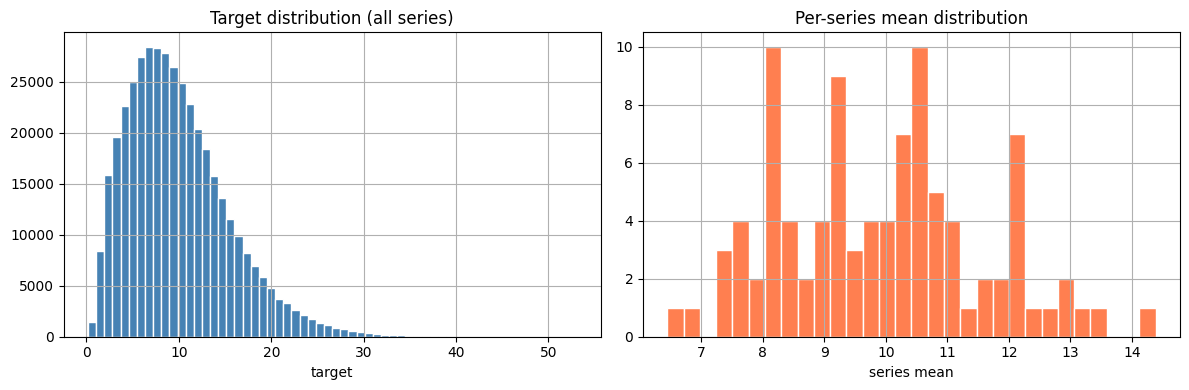

In [5]:
# ── Target distribution ───────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train_df["target"].hist(bins=60, ax=axes[0], color="steelblue", edgecolor="white")
axes[0].set_title("Target distribution (all series)")
axes[0].set_xlabel("target")
summary["mean"].hist(bins=30, ax=axes[1], color="coral", edgecolor="white")
axes[1].set_title("Per-series mean distribution")
axes[1].set_xlabel("series mean")
plt.tight_layout()
plt.show()

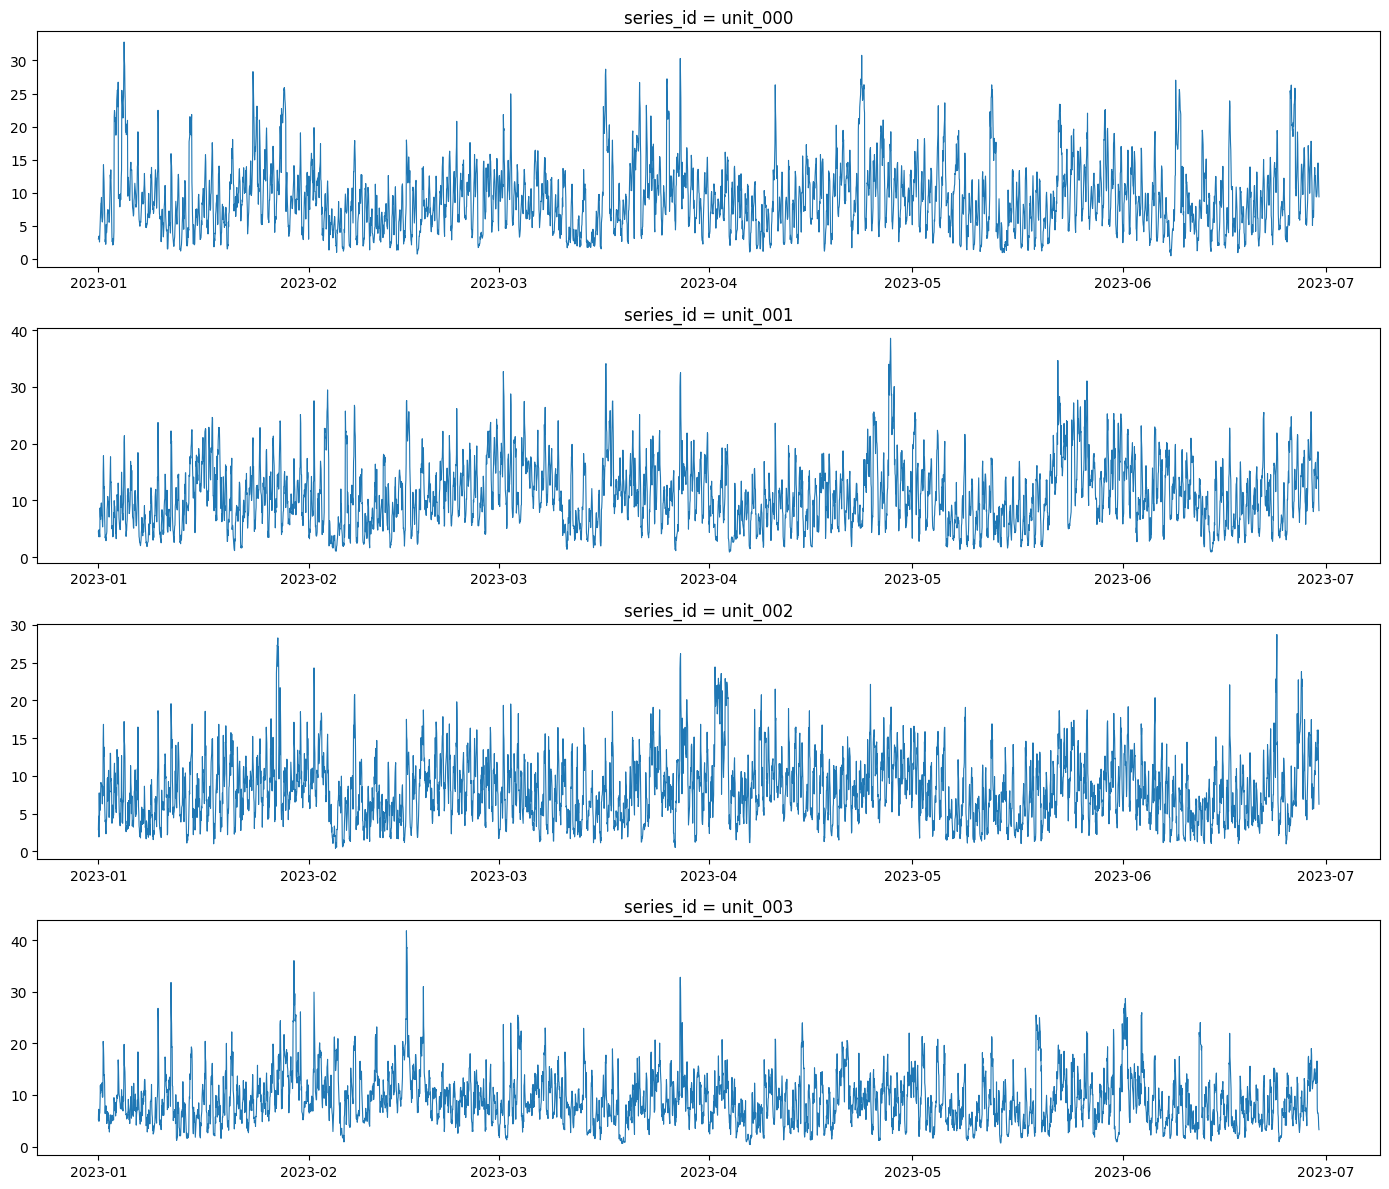

In [6]:
# ── Plot a few series ─────────────────────────────────────────────────────────
N_PLOT = 4
fig, axes = plt.subplots(N_PLOT, 1, figsize=(14, 3 * N_PLOT))
for ax, sid in zip(axes, series_ids[:N_PLOT]):
    s = train_df[train_df["series_id"] == sid].sort_values("timestamp")
    ax.plot(s["timestamp"], s["target"], linewidth=0.8)
    ax.set_title(f"series_id = {sid}")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.tight_layout()
plt.show()

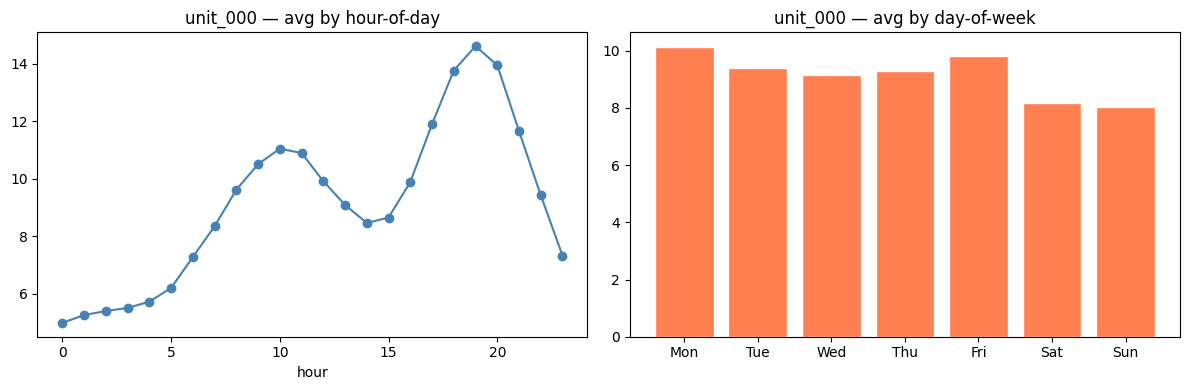

In [7]:
# ── Hourly / daily patterns for one series ────────────────────────────────────
sid_ex = series_ids[0]
s = train_df[train_df["series_id"] == sid_ex].copy()
s["hour"]      = s["timestamp"].dt.hour
s["dayofweek"] = s["timestamp"].dt.dayofweek

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
s.groupby("hour")["target"].mean().plot(ax=axes[0], marker="o", color="steelblue")
axes[0].set_title(f"{sid_ex} — avg by hour-of-day")

dow_means = s.groupby("dayofweek")["target"].mean()
axes[1].bar(dow_means.index, dow_means.values, color="coral", edgecolor="white")
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"])
axes[1].set_title(f"{sid_ex} — avg by day-of-week")
plt.tight_layout()
plt.show()

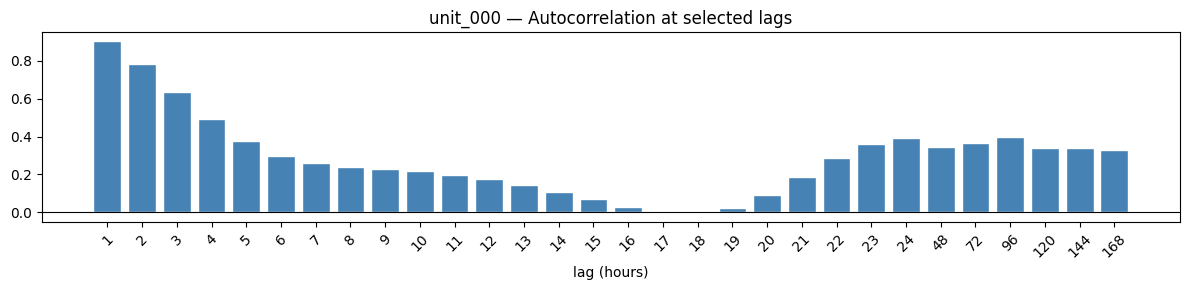

In [8]:
# ── Autocorrelation ───────────────────────────────────────────────────────────
target_vals = s.sort_values("timestamp")["target"].values
lags = list(range(1, 25)) + [48, 72, 96, 120, 144, 168]
acf  = [pd.Series(target_vals).autocorr(lag=l) for l in lags]

plt.figure(figsize=(12, 3))
plt.bar(range(len(lags)), acf, color="steelblue", edgecolor="white")
plt.xticks(range(len(lags)), lags, rotation=45)
plt.axhline(0, color="black", linewidth=0.8)
plt.title(f"{sid_ex} — Autocorrelation at selected lags")
plt.xlabel("lag (hours)")
plt.tight_layout()
plt.show()

---
## 5. Baselines & Evaluation Metrics

> **Note:** `val_input_df` has no `target` column — the validation ground truth is private.
> We evaluate baselines on the **last 336 hours of each training series** as a proxy.

In [9]:
# ── Metric functions ──────────────────────────────────────────────────────────
def mae(y_true, y_pred):                return np.mean(np.abs(y_true - y_pred))
def mse(y_true, y_pred):                return np.mean((y_true - y_pred) ** 2)
def rmse(y_true, y_pred):               return np.sqrt(mse(y_true, y_pred))
def mape(y_true, y_pred, eps=1e-8):     return np.mean(np.abs((y_true - y_pred) / (np.abs(y_true) + eps))) * 100
def smape(y_true, y_pred, eps=1e-8):    return np.mean(np.abs(y_true - y_pred) / ((np.abs(y_true) + np.abs(y_pred)) / 2 + eps)) * 100
def wape(y_true, y_pred, eps=1e-8):     return np.sum(np.abs(y_true - y_pred)) / (np.sum(np.abs(y_true)) + eps) * 100

def evaluate(y_true, y_pred, label=""):
    metrics = dict(MAE=mae(y_true,y_pred), MSE=mse(y_true,y_pred), RMSE=rmse(y_true,y_pred),
                   MAPE=mape(y_true,y_pred), sMAPE=smape(y_true,y_pred), WAPE=wape(y_true,y_pred))
    prefix = f"[{label}] " if label else ""
    for name, val in metrics.items():
        print(f"  {prefix}{name:6s} = {val:.4f}")
    return metrics

In [10]:
# ── Build held-out eval split from train tail ─────────────────────────────────
held_out_rows, held_out_index_rows = [], []
for sid, grp in train_df.groupby("series_id", sort=False):
    grp = grp.sort_values("timestamp")
    held_out = grp.tail(EVAL_HORIZON)
    held_out_rows.append(held_out)
    held_out_index_rows.append(held_out[["series_id", "timestamp"]])

held_out_gt    = pd.concat(held_out_rows,       ignore_index=True)
held_out_index = pd.concat(held_out_index_rows, ignore_index=True)

train_eval_df = train_df.merge(
    held_out_gt[["series_id", "timestamp"]],
    on=["series_id", "timestamp"], how="left", indicator=True
).query('_merge == "left_only"').drop(columns="_merge")

print(f"Full train rows   : {len(train_df):,}")
print(f"Eval context rows : {len(train_eval_df):,}")
print(f"Held-out GT rows  : {len(held_out_gt):,}")

Full train rows   : 414,720
Eval context rows : 382,464
Held-out GT rows  : 32,256


In [11]:
# ── Run and evaluate baselines ────────────────────────────────────────────────
baseline_preds_eval = make_all_baselines(train_eval_df, held_out_index)

all_metrics = {}
for name, pred_df in baseline_preds_eval.items():
    merged = held_out_index.merge(
        pred_df, on=["series_id", "timestamp"], how="left"
    ).merge(
        held_out_gt[["series_id", "timestamp", "target"]],
        on=["series_id", "timestamp"], how="left"
    )
    y_true = merged["target"].to_numpy(dtype=float)
    y_pred = merged["prediction"].to_numpy(dtype=float)
    mask   = ~(np.isnan(y_true) | np.isnan(y_pred))
    print(f"\n{'='*40}")
    all_metrics[name] = evaluate(y_true[mask], y_pred[mask], label=name)

print("\n── MAE summary (held-out train tail) ────")
for name, m in all_metrics.items():
    print(f"  {name:20s}  {m['MAE']:.4f}")


  [naive_last_value] MAE    = 5.8214
  [naive_last_value] MSE    = 57.0340
  [naive_last_value] RMSE   = 7.5521
  [naive_last_value] MAPE   = 55.6490
  [naive_last_value] sMAPE  = 65.7320
  [naive_last_value] WAPE   = 54.5040

  [lag24_repeat] MAE    = 4.4646
  [lag24_repeat] MSE    = 34.6364
  [lag24_repeat] RMSE   = 5.8853
  [lag24_repeat] MAPE   = 48.5955
  [lag24_repeat] sMAPE  = 49.4996
  [lag24_repeat] WAPE   = 41.8006

  [lag168_repeat] MAE    = 4.8584
  [lag168_repeat] MSE    = 40.4624
  [lag168_repeat] RMSE   = 6.3610
  [lag168_repeat] MAPE   = 54.0731
  [lag168_repeat] sMAPE  = 54.4251
  [lag168_repeat] WAPE   = 45.4876

  [seasonal_mean] MAE    = 3.3541
  [seasonal_mean] MSE    = 20.6407
  [seasonal_mean] RMSE   = 4.5432
  [seasonal_mean] MAPE   = 42.8468
  [seasonal_mean] sMAPE  = 34.6992
  [seasonal_mean] WAPE   = 31.4038

── MAE summary (held-out train tail) ────
  naive_last_value      5.8214
  lag24_repeat          4.4646
  lag168_repeat         4.8584
  seasonal_mean 

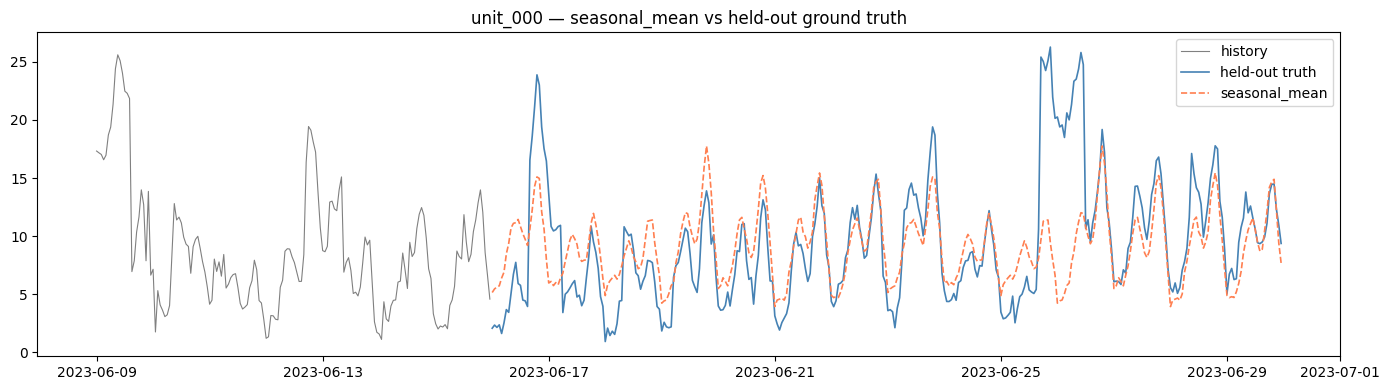

In [12]:
# ── Visualise one baseline ────────────────────────────────────────────────────
VIS_SERIES       = series_ids[0]
BASELINE_TO_PLOT = "seasonal_mean"

gt_s   = held_out_gt[held_out_gt["series_id"] == VIS_SERIES].sort_values("timestamp")
pred_s = baseline_preds_eval[BASELINE_TO_PLOT]
pred_s = pred_s[pred_s["series_id"] == VIS_SERIES].sort_values("timestamp")
hist_s = train_eval_df[train_eval_df["series_id"] == VIS_SERIES].sort_values("timestamp").tail(168)

plt.figure(figsize=(14, 4))
plt.plot(hist_s["timestamp"], hist_s["target"],     label="history",        color="gray",      linewidth=0.8)
plt.plot(gt_s["timestamp"],   gt_s["target"],       label="held-out truth", color="steelblue", linewidth=1.2)
plt.plot(pred_s["timestamp"], pred_s["prediction"], label=BASELINE_TO_PLOT, color="coral",     linewidth=1.2, linestyle="--")
plt.legend()
plt.title(f"{VIS_SERIES} — {BASELINE_TO_PLOT} vs held-out ground truth")
plt.tight_layout()
plt.show()

---
## 6. Feature Engineering

`val_input_df` provides pre-computed domain features for the forecast window:
`workload_intensity`, `demand_forecast`, `shock_risk`, `trend`, etc.
For **training** we compute compatible time + lag + rolling features from `train_df`.

In [13]:
def add_time_features(df, time_col="timestamp"):
    df = df.copy()
    t = pd.to_datetime(df[time_col])
    df["hour_sin"]   = np.sin(2 * np.pi * t.dt.hour / 24)
    df["hour_cos"]   = np.cos(2 * np.pi * t.dt.hour / 24)
    df["dow_sin"]    = np.sin(2 * np.pi * t.dt.dayofweek / 7)
    df["dow_cos"]    = np.cos(2 * np.pi * t.dt.dayofweek / 7)
    df["doy_sin"]    = np.sin(2 * np.pi * t.dt.dayofyear / 365)
    df["doy_cos"]    = np.cos(2 * np.pi * t.dt.dayofyear / 365)
    df["is_weekend"] = (t.dt.dayofweek >= 5).astype(float)
    return df

def add_lag_features(df, lags, target_col="target"):
    df = df.copy().sort_values(["series_id", "timestamp"])
    for lag in lags:
        df[f"lag_{lag}"] = df.groupby("series_id")[target_col].shift(lag)
    return df

def add_rolling_features(df, windows, target_col="target"):
    df = df.copy().sort_values(["series_id", "timestamp"])
    for w in windows:
        grp = df.groupby("series_id")[target_col]
        df[f"roll_mean_{w}"] = grp.transform(lambda x: x.shift(1).rolling(w, min_periods=1).mean())
        df[f"roll_std_{w}"]  = grp.transform(lambda x: x.shift(1).rolling(w, min_periods=1).std().fillna(0))
    return df

def normalise_target(df, norm_stats):
    df = df.merge(norm_stats.reset_index(), on="series_id", how="left")
    df["target_norm"] = (df["target"] - df["target_mean"]) / df["target_std"]
    return df


# Feature columns used by the model (must be computable from train_df)
FEATURE_COLS = (
    ["hour_sin", "hour_cos", "dow_sin", "dow_cos", "doy_sin", "doy_cos", "is_weekend"]
    + [f"lag_{l}" for l in LAGS]
    + [f"roll_mean_{w}" for w in WINDOWS]
    + [f"roll_std_{w}"  for w in WINDOWS]
)

# Per-series normalisation stats
norm_stats = (
    train_df.groupby("series_id")["target"]
    .agg(target_mean="mean", target_std="std")
)
norm_stats["target_std"] = norm_stats["target_std"].replace(0, 1.0)

# Build training feature frame
feat_df = add_time_features(train_df)
feat_df = add_lag_features(feat_df, lags=LAGS)
feat_df = add_rolling_features(feat_df, windows=WINDOWS)
feat_df = normalise_target(feat_df, norm_stats)
feat_df = feat_df.dropna(subset=FEATURE_COLS)

print(f"Feature columns ({len(FEATURE_COLS)}): {FEATURE_COLS}")
print(f"Feature frame shape: {feat_df.shape}")
feat_df.head(3)

Feature columns (21): ['hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'doy_sin', 'doy_cos', 'is_weekend', 'lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'lag_24', 'lag_48', 'lag_168', 'roll_mean_6', 'roll_mean_24', 'roll_mean_168', 'roll_std_6', 'roll_std_24', 'roll_std_168']
Feature frame shape: (398592, 44)


,series_id,timestamp,hour_sin,hour_cos,dow_sin,dow_cos,is_weekend,trend,workload_intensity,demand_forecast,...,lag_168,roll_mean_6,roll_std_6,roll_mean_24,roll_std_24,roll_mean_168,roll_std_168,target_mean,target_std,target_norm
168,unit_000,2023-01-08 00:00:00,0.000000,1.000000,-0.781831,0.62349,1.0,-1.615124,0.001633,0.000000,...,2.989556,9.809046,2.574784,8.026581,2.231346,11.419906,6.986540,9.141582,5.083139,-0.862423
169,unit_000,2023-01-08 01:00:00,0.258819,0.965926,-0.781831,0.62349,1.0,-1.614430,0.004694,0.000000,...,3.199527,8.739943,3.160582,7.976535,2.292374,11.430431,6.975087,9.141582,5.083139,-0.750965
170,unit_000,2023-01-08 02:00:00,0.500000,0.866025,-0.781831,0.62349,1.0,-1.613736,0.012069,0.072132,...,3.425670,7.476135,2.633015,7.965633,2.304826,11.443079,6.961987,9.141582,5.083139,-0.871572


---
## 7. PyTorch Dataset & DataLoader

In [ ]:
class SlidingWindowDataset(Dataset):
    """
    X : (lookback, n_features)  float32
    y : (horizon,)              float32  normalised targets
    """
    def __init__(self, df, feature_cols, target_col="target_norm",
                 lookback=LOOKBACK, horizon=HORIZON):
        self.samples = []
        for _, grp in df.groupby("series_id", sort=False):
            grp   = grp.sort_values("timestamp")
            X_arr = grp[feature_cols].to_numpy(dtype=np.float32)
            y_arr = grp[target_col].to_numpy(dtype=np.float32)
            n     = len(grp)
            for start in range(0, n - lookback - horizon + 1):
                self.samples.append((
                    X_arr[start : start + lookback],
                    y_arr[start + lookback : start + lookback + horizon],
                ))

    def __len__(self):          return len(self.samples)
    def __getitem__(self, idx):
        X, y = self.samples[idx]
        return torch.from_numpy(X), torch.from_numpy(y)


train_rows, val_rows = [], []
for sid, grp in feat_df.groupby("series_id", sort=False):
    grp = grp.sort_values("timestamp")
    train_rows.append(grp.iloc[:-EVAL_HORIZON])   # all but last 336 hours
    val_rows.append(grp.iloc[-EVAL_HORIZON:])      # last 336 hours

train_feat_df = pd.concat(train_rows, ignore_index=True)
val_feat_df   = pd.concat(val_rows,   ignore_index=True)

train_dataset = SlidingWindowDataset(train_feat_df, FEATURE_COLS)
val_dataset   = SlidingWindowDataset(val_feat_df,   FEATURE_COLS)


train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)

print(f"Train windows : {len(train_dataset):,}")
print(f"Val windows   : {len(val_dataset):,}")
xb, yb = next(iter(train_loader))
print(f"Batch X : {tuple(xb.shape)}   Batch y : {tuple(yb.shape)}")

Train windows : 342,231
Val windows   : 38,025
Batch X : (256, 168, 21)   Batch y : (256, 24)


---
## 8. Model Definition

Pick one architecture — change the one line in the last cell of this section.

In [15]:
class MLPForecaster(nn.Module):
    def __init__(self, n_features, lookback=LOOKBACK, horizon=HORIZON, hidden=256, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(lookback * n_features, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden),                nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, horizon),
        )
    def forward(self, x): return self.net(x)


class LSTMForecaster(nn.Module):
    def __init__(self, n_features, horizon=HORIZON, hidden=128, n_layers=2, dropout=0.1):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, n_layers, batch_first=True,
                            dropout=dropout if n_layers > 1 else 0.0)
        self.head = nn.Linear(hidden, horizon)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1])


class TransformerForecaster(nn.Module):
    def __init__(self, n_features, horizon=HORIZON, d_model=64, nhead=4, n_layers=2, dim_ff=256, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(n_features, d_model)
        self.encoder    = nn.TransformerEncoder(
            nn.TransformerEncoderLayer(d_model, nhead, dim_ff, dropout, batch_first=True),
            num_layers=n_layers
        )
        self.head = nn.Linear(d_model, horizon)
    def forward(self, x):
        z = self.encoder(self.input_proj(x))
        return self.head(z[:, -1])

In [16]:
# ── Pick your architecture here ───────────────────────────────────────────────
N_FEATURES = len(FEATURE_COLS)

model = LSTMForecaster(n_features=N_FEATURES, hidden=256, n_layers=2)
# model = MLPForecaster(n_features=N_FEATURES)
# model = TransformerForecaster(n_features=N_FEATURES)

model = model.to(DEVICE)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"\nTrainable parameters: {n_params:,}")

LSTMForecaster(
  (lstm): LSTM(21, 256, num_layers=2, batch_first=True, dropout=0.1)
  (head): Linear(in_features=256, out_features=24, bias=True)
)

Trainable parameters: 818,200


---
## 9. Training Loop

In [17]:
criterion = nn.HuberLoss(delta=1.0)    # swap for nn.L1Loss() to train on MAE
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=N_EPOCHS)


def run_epoch(loader, model, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, n = 0.0, 0
    with torch.set_grad_enabled(training):
        for X, y in loader:
            X, y = X.to(DEVICE), y.to(DEVICE)
            pred = model(X)
            loss = criterion(pred, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            total_loss += loss.item() * len(X)
            n += len(X)
    return total_loss / n


history = {"train": [], "val": []}
best_val_loss = float("inf")

for epoch in range(1, N_EPOCHS + 1):
    train_loss = run_epoch(train_loader, model, criterion, optimizer)
    val_loss   = run_epoch(val_loader,   model, criterion)
    scheduler.step()
    history["train"].append(train_loss)
    history["val"].append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save({"state_dict": model.state_dict(), "epoch": epoch}, CHECKPOINT_PATH)

    print(f"Epoch {epoch:3d}/{N_EPOCHS}  "
          f"train={train_loss:.5f}  val={val_loss:.5f}  "
          f"lr={scheduler.get_last_lr()[0]:.2e}" +
          ("  ← best" if val_loss == best_val_loss else ""))

print(f"\nBest val loss: {best_val_loss:.5f} → {CHECKPOINT_PATH}")

Epoch   1/100  train=0.21973  val=0.19641  lr=1.00e-03  ← best
Epoch   2/100  train=0.17771  val=0.15699  lr=9.99e-04  ← best
Epoch   3/100  train=0.14035  val=0.12334  lr=9.98e-04  ← best
Epoch   4/100  train=0.10605  val=0.09380  lr=9.96e-04  ← best
Epoch   5/100  train=0.08405  val=0.07669  lr=9.94e-04  ← best
Epoch   6/100  train=0.07181  val=0.06639  lr=9.91e-04  ← best
Epoch   7/100  train=0.06449  val=0.06063  lr=9.88e-04  ← best
Epoch   8/100  train=0.05993  val=0.05713  lr=9.84e-04  ← best
Epoch   9/100  train=0.05595  val=0.05317  lr=9.80e-04  ← best
Epoch  10/100  train=0.05328  val=0.05086  lr=9.76e-04  ← best
Epoch  11/100  train=0.05059  val=0.04844  lr=9.70e-04  ← best
Epoch  12/100  train=0.04897  val=0.04660  lr=9.65e-04  ← best
Epoch  13/100  train=0.04703  val=0.04480  lr=9.59e-04  ← best
Epoch  14/100  train=0.04620  val=0.04275  lr=9.52e-04  ← best
Epoch  15/100  train=0.04368  val=0.04262  lr=9.46e-04  ← best
Epoch  16/100  train=0.04290  val=0.04068  lr=9.38e-04 

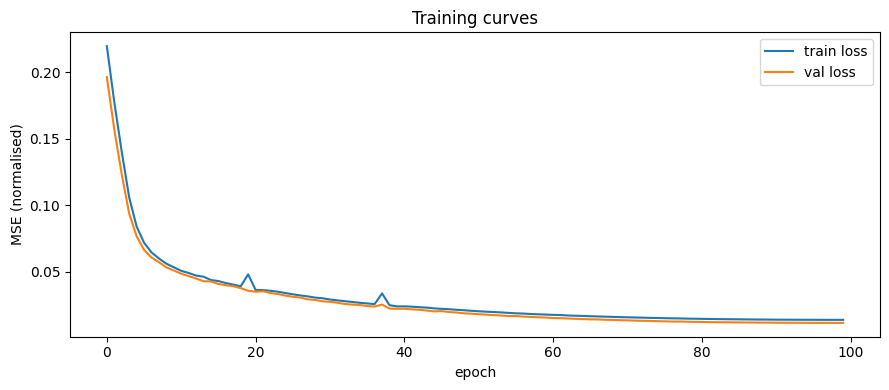

In [18]:
# ── Loss curves ───────────────────────────────────────────────────────────────
plt.figure(figsize=(9, 4))
plt.plot(history["train"], label="train loss")
plt.plot(history["val"],   label="val loss")
plt.xlabel("epoch")
plt.ylabel("MSE (normalised)")
plt.title("Training curves")
plt.legend()
plt.tight_layout()
plt.show()

---
## 10. Validation Inference

Rolls the model forward 24 steps at a time until all 336 forecast timestamps
per series are covered.  Then re-runs on the held-out train tail so we can
compute a local MAE estimate without needing the private labels.

In [19]:
# ── Load best checkpoint ──────────────────────────────────────────────────────
ckpt = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
model.load_state_dict(ckpt["state_dict"])
model.eval()
print(f"Loaded checkpoint from epoch {ckpt['epoch']}")


def make_window(ctx, feature_cols, lookback=LOOKBACK):
    X = ctx.tail(lookback)[feature_cols].to_numpy(dtype=np.float32)
    if len(X) < lookback:
        X = np.vstack([np.zeros((lookback - len(X), X.shape[1]), dtype=np.float32), X])
    return X


@torch.no_grad()
def rolling_forecast(model, context_df, index_df, norm_stats, feature_cols,
                     lookback=LOOKBACK, horizon=HORIZON):
    all_preds = []
    for sid, idx_grp in index_df.groupby("series_id", sort=False):
        idx_grp    = idx_grp.sort_values("timestamp")
        timestamps = idx_grp["timestamp"].tolist()

        ctx = context_df[context_df["series_id"] == sid].sort_values("timestamp").copy()
        ctx = add_time_features(ctx)
        ctx = add_lag_features(ctx, LAGS)
        ctx = add_rolling_features(ctx, WINDOWS)
        ctx = normalise_target(ctx, norm_stats)
        ctx = ctx.dropna(subset=feature_cols)

        mean = float(norm_stats.loc[sid, "target_mean"])
        std  = float(norm_stats.loc[sid, "target_std"])

        t_idx = 0
        while t_idx < len(timestamps):
            X_t      = torch.from_numpy(make_window(ctx, feature_cols)).unsqueeze(0).to(DEVICE)
            pred_norm = model(X_t).squeeze(0).cpu().numpy()

            n_step            = min(horizon, len(timestamps) - t_idx)
            step_norm         = pred_norm[:n_step]
            step_denorm       = np.maximum(step_norm * std + mean, 0.0)
            step_times        = timestamps[t_idx : t_idx + n_step]

            for ts, p in zip(step_times, step_denorm):
                all_preds.append({"series_id": sid, "timestamp": ts, "prediction": p})

            # Update context with predicted rows so next window has fresh lags
            combined = list(ctx["target"].values) + list(step_denorm)
            new_rows = add_time_features(
                pd.DataFrame({"series_id": sid, "timestamp": step_times, "target": step_denorm})
            )
            for lag in LAGS:
                new_rows[f"lag_{lag}"] = [
                    combined[len(ctx) + i - lag] if len(ctx) + i - lag >= 0 else np.nan
                    for i in range(n_step)
                ]
            for w in WINDOWS:
                new_rows[f"roll_mean_{w}"] = float(np.mean(combined[-w:]))
                new_rows[f"roll_std_{w}"]  = float(np.std(combined[-w:]))
            new_rows["target_mean"]  = float(mean)
            new_rows["target_std"]   = float(std)
            new_rows["target_norm"]  = step_norm
            new_rows = new_rows.fillna(0.0)
            ctx   = pd.concat([ctx, new_rows], ignore_index=True)
            t_idx += n_step

    return pd.DataFrame(all_preds)

Loaded checkpoint from epoch 99


In [20]:
# ── Generate competition predictions ─────────────────────────────────────────
predictions_df = rolling_forecast(model, train_df, val_index_df, norm_stats, FEATURE_COLS)
print(f"Predictions: {len(predictions_df):,} rows  (expected {len(val_index_df):,})")
predictions_df.head()

Predictions: 32,256 rows  (expected 32,256)


,series_id,timestamp,prediction
0,unit_000,2023-06-30 00:00:00,7.520605
1,unit_000,2023-06-30 01:00:00,6.646152
2,unit_000,2023-06-30 02:00:00,6.308248
3,unit_000,2023-06-30 03:00:00,6.101898
4,unit_000,2023-06-30 04:00:00,5.862737


In [21]:
# ── Local evaluation on held-out train tail ───────────────────────────────────
eval_preds_df = rolling_forecast(model, train_eval_df, held_out_index, norm_stats, FEATURE_COLS)

eval_merged = held_out_index.merge(
    eval_preds_df, on=["series_id", "timestamp"], how="left"
).merge(
    held_out_gt[["series_id", "timestamp", "target"]], on=["series_id", "timestamp"], how="left"
)
y_true_e = eval_merged["target"].to_numpy(dtype=float)
y_pred_e = eval_merged["prediction"].to_numpy(dtype=float)
mask_e   = ~(np.isnan(y_true_e) | np.isnan(y_pred_e))

print("── Model (held-out train tail) ───────────")
model_metrics = evaluate(y_true_e[mask_e], y_pred_e[mask_e], label="model")
print(f"\n── vs. seasonal_mean baseline ────────────")
print(f"  seasonal_mean MAE = {all_metrics['seasonal_mean']['MAE']:.4f}")
print(f"  model         MAE = {model_metrics['MAE']:.4f}")
delta = (all_metrics['seasonal_mean']['MAE'] - model_metrics['MAE']) / all_metrics['seasonal_mean']['MAE'] * 100
print(f"  Improvement       = {delta:+.1f}%")

── Model (held-out train tail) ───────────
  [model] MAE    = 2.9106
  [model] MSE    = 16.8750
  [model] RMSE   = 4.1079
  [model] MAPE   = 37.1365
  [model] sMAPE  = 29.1908
  [model] WAPE   = 27.2513

── vs. seasonal_mean baseline ────────────
  seasonal_mean MAE = 3.3541
  model         MAE = 2.9106
  Improvement       = +13.2%


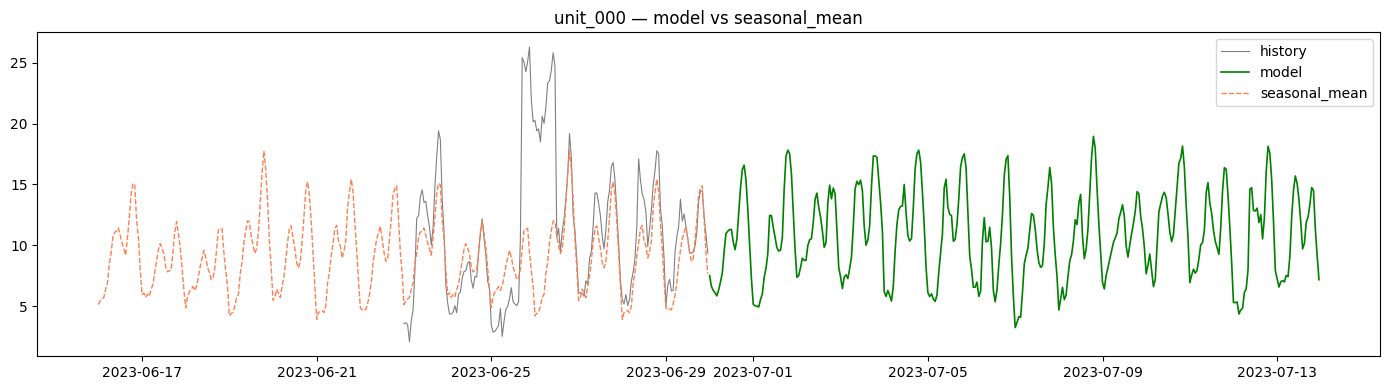

In [22]:
# ── Visual comparison ─────────────────────────────────────────────────────────
VIS_SERIES = series_ids[0]

pred_s = predictions_df[predictions_df["series_id"] == VIS_SERIES].sort_values("timestamp")
base_s = baseline_preds_eval["seasonal_mean"]
base_s = base_s[base_s["series_id"] == VIS_SERIES].sort_values("timestamp")
hist_s = train_df[train_df["series_id"] == VIS_SERIES].sort_values("timestamp").tail(168)

plt.figure(figsize=(14, 4))
plt.plot(hist_s["timestamp"], hist_s["target"],     label="history",       color="gray",  linewidth=0.8)
plt.plot(pred_s["timestamp"], pred_s["prediction"], label="model",         color="green", linewidth=1.2)
plt.plot(base_s["timestamp"], base_s["prediction"], label="seasonal_mean", color="coral", linewidth=1.0, linestyle="--")
plt.legend()
plt.title(f"{VIS_SERIES} — model vs seasonal_mean")
plt.tight_layout()
plt.show()

---
## 11. Save & Submit

In [23]:
# ── Save predictions CSV ──────────────────────────────────────────────────────
predictions_df[["series_id", "timestamp", "prediction"]].to_csv(VAL_PREDS_PATH, index=False)
print(f"Predictions saved  → {VAL_PREDS_PATH}")
print(f"Checkpoint saved   → {CHECKPOINT_PATH}")
print("\nDownload both files from the Kaggle output panel to add to your submission.")

Predictions saved  → /kaggle/working/validation_predictions.csv
Checkpoint saved   → /kaggle/working/best_checkpoint.pt

Download both files from the Kaggle output panel to add to your submission.


---
### Quick reference

| What to change | Where |
|---|---|
| Input / output paths | **Section 1 — Config** |
| Batch size, epochs, LR | **Section 1 — Config** |
| Lookback window, horizon | **Section 1 — Config** |
| Lag / rolling window sizes | **Section 1 — Config** |
| Model architecture | **Section 8** — swap one line |
| Loss function | **Section 9** — `nn.MSELoss()` → `nn.L1Loss()` |
| Series to visualise | `VIS_SERIES` in Sections 5 / 10 |